# Practical 2: Dimensionality Reduction with PCA and LDA

**Aim:** Use PCA and LDA on a dataset with many features and see how reducing the features changes model accuracy and speed.

**Dataset:** Breast Cancer (569 patients, **30 features**, 2 classes). Built into scikit-learn.

**Steps:** 1) Load, split, scale  2) Baseline model on all 30 features  3) PCA  4) LDA  5) Compare  6) Plot PCA and LDA

## Step 1: Load, split and scale

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

data = load_breast_cancer()
X = data.data
y = data.target
print("Samples:", X.shape[0], " Features:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# PCA needs scaled data (otherwise big-valued features dominate)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

Samples: 569  Features: 30


## Step 2: Baseline model (all 30 features)

In [2]:
# A small helper: train logistic regression, return accuracy and time taken
def train_and_test(name, X_tr, X_te):
    start = time.time()
    model = LogisticRegression(max_iter=1000)
    model.fit(X_tr, y_train)
    seconds = time.time() - start
    acc = accuracy_score(y_test, model.predict(X_te))
    return {"Model": name, "Features": X_tr.shape[1],
            "Accuracy": round(acc, 4), "Train time (sec)": round(seconds, 4)}

results = []
results.append(train_and_test("All features", X_train_s, X_test_s))
results[0]

{'Model': 'All features',
 'Features': 30,
 'Accuracy': 0.9825,
 'Train time (sec)': 0.0097}

## Step 3: PCA
PCA (unsupervised, it ignores the labels) makes new features called principal components. The first one keeps the most information (variance), the next keeps the next most, and so on.

Components needed to keep 95% of the information: 10 out of 30


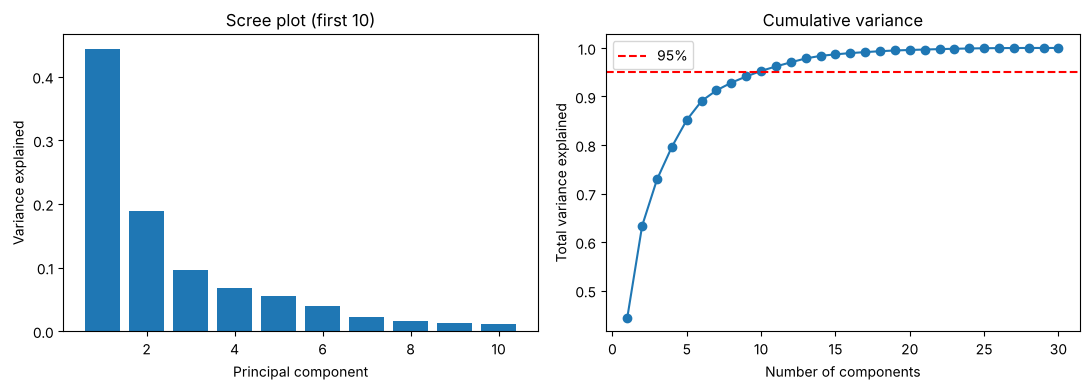

In [3]:
pca = PCA()
pca.fit(X_train_s)

ratio = pca.explained_variance_ratio_      # variance kept by each component
cumulative = np.cumsum(ratio)              # running total

n95 = np.argmax(cumulative >= 0.95) + 1    # first point where we keep 95%
print("Components needed to keep 95% of the information:", n95, "out of 30")

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.bar(range(1, 11), ratio[:10])
plt.xlabel("Principal component")
plt.ylabel("Variance explained")
plt.title("Scree plot (first 10)")

plt.subplot(1, 2, 2)
plt.plot(range(1, 31), cumulative, marker="o")
plt.axhline(0.95, color="red", linestyle="--", label="95%")
plt.xlabel("Number of components")
plt.ylabel("Total variance explained")
plt.title("Cumulative variance")
plt.legend()

plt.tight_layout()
plt.show()

**How to read:**
- **Scree plot:** each bar is how much information one component keeps. The first bar is tallest and they drop quickly, so only a few components matter.
- **Cumulative plot:** the red line is 95%. Where the curve crosses it tells you how many components to keep (about 10 here instead of 30).

In [4]:
# PCA with 2 components
pca2 = PCA(n_components=2)
X_train_p2 = pca2.fit_transform(X_train_s)
X_test_p2 = pca2.transform(X_test_s)
results.append(train_and_test("PCA (2 components)", X_train_p2, X_test_p2))

# PCA that keeps 95% of the information
pca95 = PCA(n_components=0.95)
X_train_p95 = pca95.fit_transform(X_train_s)
X_test_p95 = pca95.transform(X_test_s)
results.append(train_and_test("PCA (95% variance)", X_train_p95, X_test_p95))

## Step 4: LDA
LDA (supervised, it **uses the labels**) finds the axis that separates the classes best. With 2 classes it gives at most 1 component (classes - 1).

In [5]:
lda = LinearDiscriminantAnalysis(n_components=1)
X_train_l = lda.fit_transform(X_train_s, y_train)   # note: LDA needs y
X_test_l = lda.transform(X_test_s)
results.append(train_and_test("LDA (1 component)", X_train_l, X_test_l))

## Step 5: Compare accuracy and time

                Model  Features  Accuracy  Train time (sec)
0        All features        30    0.9825            0.0097
1  PCA (2 components)         2    0.9474            0.0038
2  PCA (95% variance)        10    0.9737            0.0049
3   LDA (1 component)         1    0.9737            0.0033


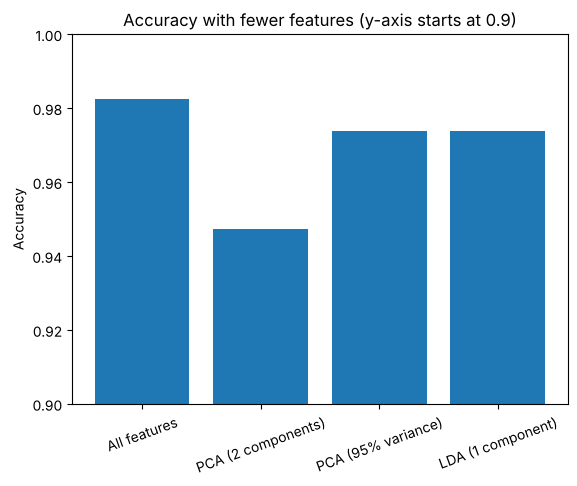

In [6]:
table = pd.DataFrame(results)
print(table)

plt.bar(table["Model"], table["Accuracy"])
plt.ylim(0.9, 1.0)
plt.xticks(rotation=20)
plt.ylabel("Accuracy")
plt.title("Accuracy with fewer features (y-axis starts at 0.9)")
plt.show()

**How to read:** accuracy stays close to the full 30-feature model even with 10, 2 or 1 feature, so most of the information was repeated. The 2-component PCA loses a few points; LDA with just 1 feature does very well because it uses the labels. The training times are tiny on this small dataset, so the differences are mostly noise; the time saving is real only for big datasets.

## Step 6: Plot PCA and LDA

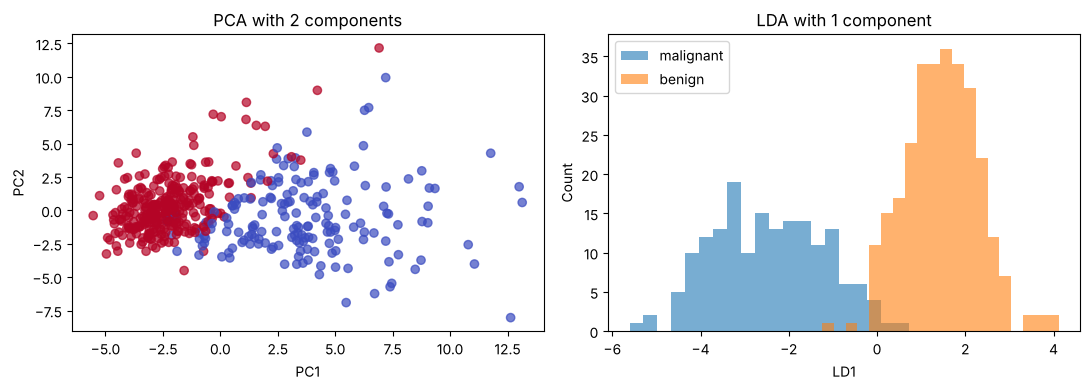

In [7]:
plt.figure(figsize=(11, 4))

# PCA scatter: each dot is a patient, colour = class
plt.subplot(1, 2, 1)
plt.scatter(X_train_p2[:, 0], X_train_p2[:, 1], c=y_train, cmap="coolwarm", alpha=0.7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA with 2 components")

# LDA histogram: 1 axis, one histogram per class
plt.subplot(1, 2, 2)
plt.hist(X_train_l[y_train == 0], bins=20, alpha=0.6, label="malignant")
plt.hist(X_train_l[y_train == 1], bins=20, alpha=0.6, label="benign")
plt.xlabel("LD1")
plt.ylabel("Count")
plt.title("LDA with 1 component")
plt.legend()

plt.tight_layout()
plt.show()

**How to read:**
- **PCA scatter:** PC1 is the direction with the most variance, PC2 the next one. The two colours are mostly apart even though PCA never saw the labels.
- **LDA histogram:** the two classes form two humps far apart. The small overlap in the middle is where mistakes happen.

## Conclusion
30 features were reduced to 10 (PCA), 2 (PCA) or 1 (LDA) with only a small drop in accuracy. LDA (supervised) separates classes better per component than PCA (unsupervised).

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is dimensionality reduction? Why use it?**
Reducing the number of input features while keeping most of the information. It reduces computation, storage, noise and overfitting, helps visualisation and fights the curse of dimensionality.

**Q2. What is the curse of dimensionality?**
As the number of features grows, data becomes sparse, distances lose meaning and models need exponentially more data, so they overfit easily.

**Q3. What is PCA?**
Principal Component Analysis is an unsupervised technique that transforms correlated features into a smaller set of uncorrelated variables (principal components), ordered by how much variance they capture.

**Q4. Explain the steps of PCA.**
(1) Standardise the data. (2) Compute the covariance matrix. (3) Find eigenvalues and eigenvectors. (4) Sort eigenvectors by eigenvalue, largest first. (5) Select the top k. (6) Project the data onto them.

**Q5. What are eigenvalues and eigenvectors in PCA?**
An eigenvector is a direction (a principal component). Its eigenvalue says how much variance lies along that direction.

**Q6. Why must data be scaled before PCA?**
PCA maximises variance, so features with large units dominate. Scaling gives all features equal weight.

**Q7. What is LDA?**
Linear Discriminant Analysis is a supervised technique that finds axes that maximise separation between classes (between-class variance) while minimising spread inside each class (within-class variance).

**Q8. Difference between PCA and LDA?**
PCA is unsupervised and maximises total variance; it can give up to n_features components. LDA is supervised and maximises class separability; it gives at most (number of classes - 1) components.

**Q9. Why is the maximum number of LDA components c - 1?**
With c classes the c class means lie in a space of dimension at most c - 1, so there are only c - 1 useful discriminant directions. A binary problem gives 1 component.

**Q10. Is PCA feature selection?**
No. It is feature extraction: new features are created as combinations of the old ones. Feature selection keeps a subset of original features.

**Q11. How do you choose the number of components?**
Keep enough to explain about 95% of the variance (cumulative plot), use the scree-plot elbow, or choose by validation accuracy.

**Q12. Did performance fall after reduction? Why?**
Slightly or not at all, because some information is discarded but most of it was redundant. The trade-off is lower computation and a simpler model for a small accuracy change.

**Q13. Are principal components interpretable?**
Not easily. Each is a mix of all original features. The weights (loadings) are in `pca.components_`.

**Q14. What assumptions does LDA make?**
Features are normally distributed within each class, all classes share the same covariance matrix, and classes are linearly separable.

**Q15. Is PCA affected by outliers?**
Yes, because it relies on variance and the covariance matrix, so extreme points can pull the components.

**Q16. Are principal components correlated with each other?**
No. They are orthogonal (uncorrelated) by construction.

**Q17. What is explained variance ratio?**
The fraction of total variance captured by each component. They sum to 1 over all components.

**Q18. Can PCA be used for supervised problems?**
Yes, as a preprocessing step before a classifier, but PCA itself ignores labels, so the top components are not guaranteed to be the most predictive.

**Q19. What is the difference between LDA and logistic regression?**
Both give linear boundaries. LDA is generative (models each class as a Gaussian with shared covariance) and is also used for dimensionality reduction. Logistic regression is discriminative and models the probability directly.

**Q20. Give other dimensionality reduction methods.**
t-SNE, UMAP, Kernel PCA, Autoencoders, SVD, Factor Analysis, and feature selection methods (filter, wrapper, embedded).

## B. Questions about the graphs

**G1. What does the cumulative explained variance plot show?**
X-axis: number of components. Y-axis: share of total variance captured together. It rises steeply then flattens. About 10 components keep roughly 95% of the variance, so 30 features can be cut to about 10 with little loss.

**G2. What is the dashed line at 0.95?**
A threshold. The first x-value where the curve crosses it is the number of components to keep.

**G3. What is a scree plot and how do you use it?**
A plot of variance explained by each individual component. Look for the elbow where bars drop off and keep the components before it.

**G4. What do PC1 and PC2 on the scatter plot mean?**
PC1 is the direction of maximum variance in the data; PC2 is the next direction, perpendicular to PC1. Both are linear combinations of the original features.

**G5. The two classes are separated in the PCA scatter. Why, if PCA ignores labels?**
The classes differ strongly along the directions of highest variance, so even 2 components carry most of the class information. If the points overlapped heavily, 2 components would be insufficient.

**G6. Why does the LDA plot separate classes better than PCA?**
LDA uses labels and picks the axis maximising between-class distance relative to within-class spread. PCA only maximises total variance.

**G7. What does the LDA histogram overlap represent?**
The region where the two classes cannot be distinguished along LD1. Samples in that region are the likely misclassifications.

## C. Code questions

**C1. Why `fit_transform` on train but only `transform` on test?**
To avoid data leakage. The mean and std must come from training data only.

**C2. What does `PCA(n_components=0.95)` do?**
It automatically keeps the smallest number of components whose cumulative explained variance is at least 95%.

**C3. Why does LDA need `y` in `fit` while PCA does not?**
LDA is supervised and uses class labels; PCA is unsupervised.

**C4. Why `stratify=y`?**
To keep the class proportions the same in train and test sets.